# 정류장 간 버스 통행시간 예측 — 준서 실습 기록 (앙상블 전까지)

`bis-travel-time-practice`의 베이스라인 노트북에서 출발해, **데이터 분석 → 검증 설계 → 오차 분석 → 피처 실험 → 하이퍼파라미터 조정**까지 진행한 과정을 직접 실행해 볼 수 있게 정리한 노트북임.

- **Part 1. 데이터 분석**: 버스(차량)별 / 요일별 / 시간대별 / 데이터 품질
- **Part 2. 검증 설계와 기준선**: 날짜 하나씩 빼고 학습하는 검증, 평균 예측, 시드 흔들림
- **Part 3. 오차 분석**: 어디서 많이 틀리는가
- **Part 4. 피처 실험**: 후보를 하나씩 넣어 비교
- **Part 5. 하이퍼파라미터**: 트리 크기·개수 비교
- **Part 6. 최종 설정과 연습용 test 확인**
- **Part 7. 실험 기록 요약**

> **실행 시간**: 전체 약 10~15분. 시간이 오래 걸리는 셀은 기본값을 가볍게 해 두었고(시드 1개, 작은 격자), 큰 설정은 셀 위 플래그로 바꿀 수 있음.
> 이 노트북의 숫자는 시드 1개 기준이라 README에 적은 시드 3개 평균 값과 소수 둘째 자리 정도 다를 수 있음.

---
# Part 0. 준비

필요 패키지: `numpy pandas matplotlib lightgbm pyarrow` (`requirements.txt` 참고). 데이터는 같은 상위 폴더의 `bis-travel-time-practice/data/practice/`에서 찾고, 없으면 허깅페이스에서 내려받음.

In [1]:
import os, sys, time, logging, warnings, itertools
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

warnings.filterwarnings('ignore')
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
plt.rcParams['font.family'] = ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK JP', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)

CANDIDATES = [os.environ.get('BIS_DATA'),
              '../../bis-travel-time-practice/data/practice',
              '../bis-travel-time-practice/data/practice',
              '../data/practice']
DATA = next((Path(p) for p in CANDIDATES if p and (Path(p) / 'train.parquet').exists()), None)
if DATA is None:
    from huggingface_hub import snapshot_download
    DATA = Path('../data/practice')
    snapshot_download(repo_id='CAMUS-LAB/bis-travel-time-practice', repo_type='dataset', local_dir=DATA)
print('데이터 위치:', DATA.resolve())

데이터 위치: /mnt/user-data/uploads/bis-travel-time-practice/data/practice


---
# Part 1. 데이터 분석

## 1-1. 불러오기
한 행 = **버스 한 대가 정류장 A에 도착해서 다음 정류장 B에 도착할 때까지**의 기록 하나. 맞혀야 할 값은 `tt_sec`(초).
`same_name`(출발·도착 정류장 이름이 같은 구간)과 `seg`(구간 ID) 등 몇 가지 열을 미리 붙여 둠.

In [2]:
train = pd.read_parquet(DATA / 'train.parquet')
test = pd.read_parquet(DATA / 'test.parquet')

PEAK = {7, 8, 9, 17, 18, 19}
def add_base(df):
    df = df.copy()
    d = pd.to_datetime(df.date)
    df['dow'] = d.dt.day_of_week                                   # 0=월 ... 6=일
    df['is_weekend'] = (df.dow >= 5).astype(int)
    df['is_peak'] = df.arrive_hour.isin(PEAK).astype(int)
    df['interval'] = np.select([df.dow == 5, df.dow == 6], [df.interval_sat, df.interval_sun], default=df.interval_wd)
    df['dlat'] = df.to_lat - df.from_lat
    df['dlon'] = df.to_lon - df.from_lon
    df['seg'] = df.from_stop + '>' + df.to_stop                    # 구간 ID
    df['same_name'] = (df.from_name == df.to_name)                 # 출발·도착 정류장 이름이 같은 구간
    return df

train, test = add_base(train), add_base(test)
print('train', train.shape, '| test', test.shape)

train (109891, 32) | test (79942, 32)


## 1-2. 날짜와 노선
train은 월·화·수·토, test는 목·금·일임 → **처음 보는 날짜를 맞히는 문제**임.

In [3]:
g = pd.concat([train.assign(구분='train'), test.assign(구분='test')])
day = g.groupby(['date', '구분']).agg(행수=('row_id', 'size'), 차량수=('vehicle_id', 'nunique')).reset_index()
day['요일'] = pd.to_datetime(day.date).dt.day_name().str[:3]
display(day)

route = train.groupby('route_nm').agg(행수=('tt_sec', 'size'), 차량수=('vehicle_id', 'nunique'), 정류장수=('from_stop', 'nunique'),
                                      평균통행시간=('tt_sec', 'mean'), 중앙값=('tt_sec', 'median'), 평균거리m=('dist_m', 'mean'))
route['평균속도kmh'] = train.groupby('route_nm').apply(lambda d: d.dist_m.sum() / d.tt_sec.sum() * 3.6)
display(route.round(1))

,date,구분,행수,차량수,요일
0,2024-09-23,train,28783,83,Mon
1,2024-09-24,train,28870,82,Tue
2,2024-09-25,train,28887,84,Wed
3,2024-09-26,test,28853,81,Thu
4,2024-09-27,test,28713,81,Fri
5,2024-09-28,train,23351,66,Sat
6,2024-09-29,test,22376,62,Sun


,행수,차량수,정류장수,평균통행시간,중앙값,평균거리m,평균속도kmh
route_nm,,,,,,,
1,17377,21,42,160.0,140.0,727.9,16.4
102,47679,34,88,108.9,83.0,479.8,15.9
511,20620,14,65,98.5,69.0,400.4,14.6
605,24215,20,77,115.4,93.0,466.4,14.6


## 1-3. 정답 `tt_sec`은 어떻게 생겼나
대부분 1~2분이지만 꼬리가 길다. 정류장 간 거리가 짧을수록 속도가 느림(정차 시간 비중이 커서).

0.01     22.0
0.05     33.0
0.25     56.0
0.50     89.0
0.75    150.0
0.95    256.0
0.99    534.0
600초 초과: 938행 (0.85%)


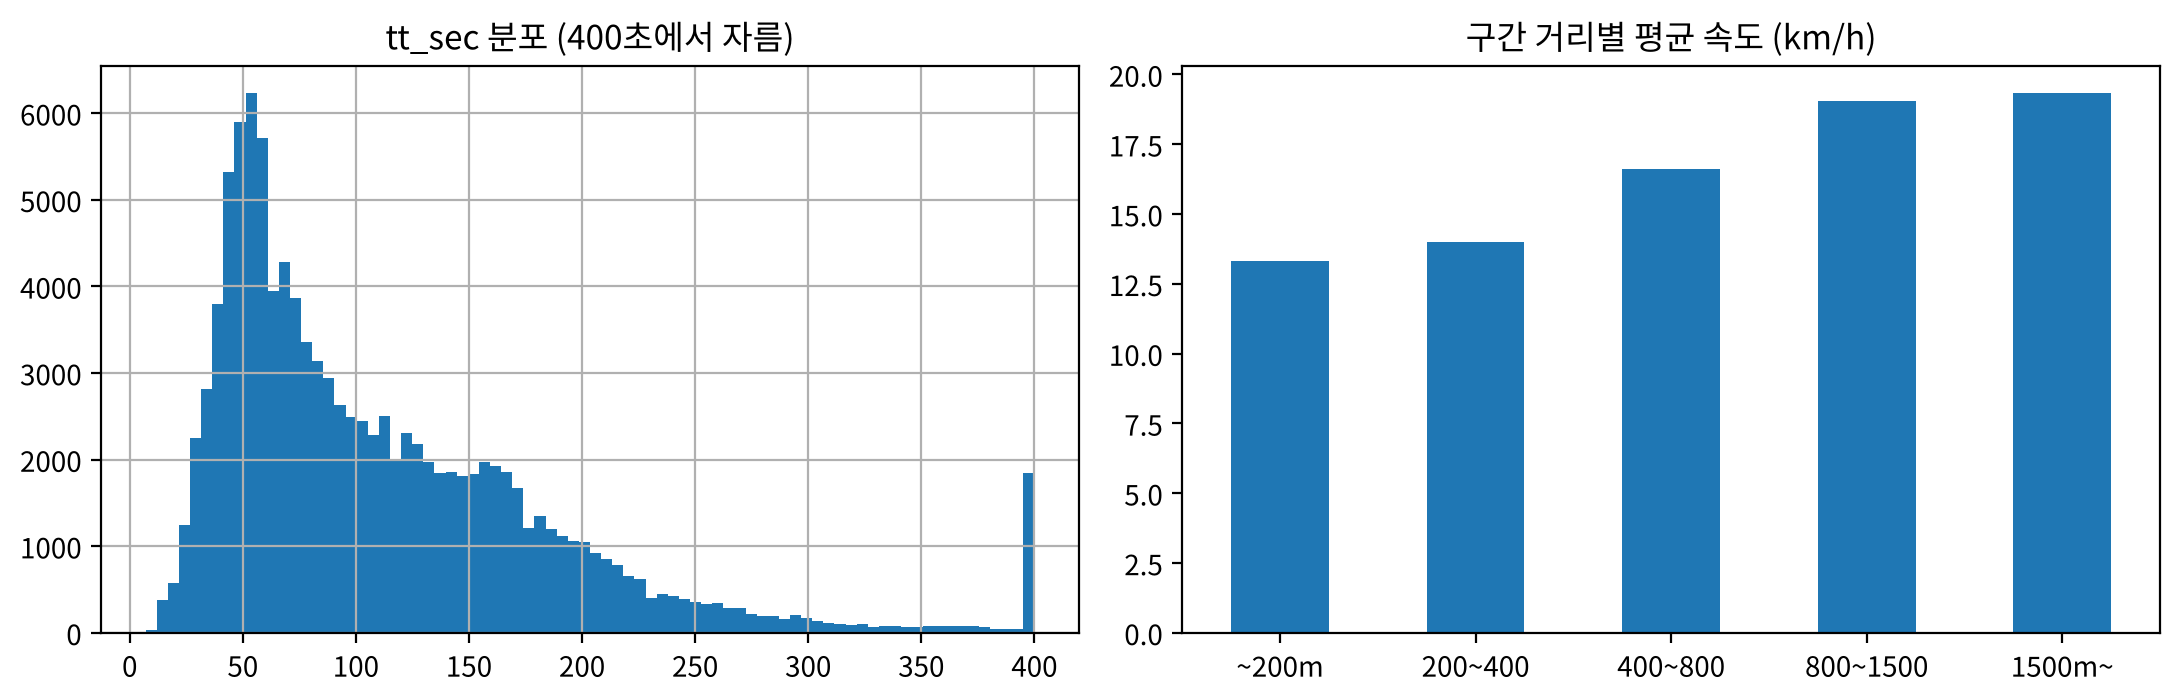

In [4]:
print(train.tt_sec.quantile([.01, .05, .25, .5, .75, .95, .99]).round(0).to_string())
print('600초 초과: %d행 (%.2f%%)' % ((train.tt_sec > 600).sum(), (train.tt_sec > 600).mean() * 100))

nlr = train[~train.same_name]
dbin = pd.cut(nlr.dist_m, [0, 200, 400, 800, 1500, 20000], labels=['~200m', '200~400', '400~800', '800~1500', '1500m~'])
speed = nlr.groupby(dbin).apply(lambda d: d.dist_m.sum() / d.tt_sec.sum() * 3.6)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
train.tt_sec.clip(upper=400).hist(bins=80, ax=ax[0]); ax[0].set_title('tt_sec 분포 (400초에서 자름)')
speed.plot.bar(ax=ax[1], rot=0); ax[1].set_title('구간 거리별 평균 속도 (km/h)'); ax[1].set_xlabel('')
plt.tight_layout(); plt.show()

## 1-4. 버스(차량)별로 확인할 것
- 차량이 노선을 넘나드는가, test 차량이 train에도 있는가
- 빠른 버스/느린 버스가 있는가 → 구간·시간대 기대값(**다른 날짜들**의 중앙값) 대비 로그비를 차량별로 보고, 날짜가 바뀌어도 유지되는지 확인

In [5]:
v_routes = train.groupby('vehicle_id').route_nm.nunique()
print('차량 수:', train.vehicle_id.nunique(), '| 두 개 이상 노선을 운행한 차량:', int((v_routes > 1).sum()))
print('test 차량 중 train에도 있는 차량 비율: %.3f' % test.vehicle_id.drop_duplicates().isin(train.vehicle_id.unique()).mean())
print('차량당 하루 평균 운행 행 수: %.0f' % train.groupby(['vehicle_id', 'date']).size().mean())

nl = train[~train.same_name].copy()
parts = []
for d in sorted(nl.date.unique()):                                  # 기대값은 '그 날짜를 뺀' 나머지 날짜로 계산
    o = nl[nl.date != d].groupby(['seg', 'arrive_hour']).tt_sec.median().rename('exp')
    parts.append(nl[nl.date == d].join(o, on=['seg', 'arrive_hour']))
x = pd.concat(parts).dropna(subset=['exp'])
x['lr'] = np.log(x.tt_sec.clip(lower=1) / x.exp)

veh = x.groupby('vehicle_id').lr.median()
print('\n차량 효과(로그비 중앙값)의 차량 간 표준편차: %.3f  (0.018이면 약 ±2%%)' % veh.std())
print('차량 효과가 날짜가 바뀌어도 이어지는가 (상관):')
display(x.groupby(['vehicle_id', 'date']).lr.median().unstack('date').corr().round(2))
x['veh_day'] = x.groupby(['vehicle_id', 'date']).lr.transform('median')
print('차량-일 효과를 알면 줄어드는 분산 비율(참고용, 같은 날 정보라 예측엔 못 씀): %.3f' % (1 - ((x.lr - x.veh_day) ** 2).mean() / (x.lr ** 2).mean()))

차량 수: 89 | 두 개 이상 노선을 운행한 차량: 0
test 차량 중 train에도 있는 차량 비율: 0.988
차량당 하루 평균 운행 행 수: 349



차량 효과(로그비 중앙값)의 차량 간 표준편차: 0.018  (0.018이면 약 ±2%)
차량 효과가 날짜가 바뀌어도 이어지는가 (상관):


date,2024-09-23,2024-09-24,2024-09-25,2024-09-28
date,,,,
2024-09-23,1.00,0.45,0.23,0.42
2024-09-24,0.45,1.00,0.47,0.34
2024-09-25,0.23,0.47,1.00,0.11
2024-09-28,0.42,0.34,0.11,1.00


차량-일 효과를 알면 줄어드는 분산 비율(참고용, 같은 날 정보라 예측엔 못 씀): 0.007


## 1-5. 요일별로 확인할 것
같은 구간의 전체 중앙값(`seg_med`) 대비 로그비 = **"평소보다 몇 % 빠른가/느린가"**. 월·화·수가 서로 비슷한지, 토요일만 다른지 본다. (회차 성격의 `same_name` 구간은 제외)

In [6]:
nl['seg_med'] = nl.groupby('seg').tt_sec.transform('median')
nl['lr_seg'] = np.log(nl.tt_sec.clip(lower=1) / nl.seg_med)

d = nl.groupby('date').agg(행수=('tt_sec', 'size'), 평균=('tt_sec', 'mean'), 중앙값=('tt_sec', 'median'),
                           평소대비=('lr_seg', 'mean'), 변동폭=('lr_seg', 'std')).round(3)
display(d)
print('노선별 평소 대비 (요일 효과):'); display(nl.groupby(['route_nm', 'date']).lr_seg.mean().unstack().round(3))
print('이름 같은 구간(same_name)의 날짜별 평균 tt:', train[train.same_name].groupby('date').tt_sec.mean().round(0).to_dict())

c = train.groupby(['seg', 'date']).tt_sec.median().unstack('date')
print('\n구간 중앙값의 날짜 간 상관 (구간 자체의 성격이 요일이 달라도 유지되는가):'); display(c.corr().round(3))
t = train.groupby(['seg', 'arrive_hour', 'date']).tt_sec.median().unstack('date')
print('구간×시간대 중앙값의 날짜 간 상관 (시간대별 모양은 얼마나 유지되는가):'); display(t.corr().round(3))

,행수,평균,중앙값,평소대비,변동폭
date,,,,,
2024-09-23,28393,111.842,89.0,0.005,0.377
2024-09-24,28465,111.976,90.0,0.013,0.377
2024-09-25,28482,111.864,90.0,0.010,0.371
2024-09-28,23021,111.447,85.0,-0.025,0.448


노선별 평소 대비 (요일 효과):


date,2024-09-23,2024-09-24,2024-09-25,2024-09-28
route_nm,,,,
1,-0.009,-0.008,-0.006,-0.029
102,0.014,0.028,0.021,-0.018
511,0.019,0.024,0.018,-0.024
605,-0.016,-0.010,-0.007,-0.036


이름 같은 구간(same_name)의 날짜별 평균 tt: {'2024-09-23': 468.0, '2024-09-24': 467.0, '2024-09-25': 460.0, '2024-09-28': 378.0}

구간 중앙값의 날짜 간 상관 (구간 자체의 성격이 요일이 달라도 유지되는가):


date,2024-09-23,2024-09-24,2024-09-25,2024-09-28
date,,,,
2024-09-23,1.000,0.994,0.983,0.926
2024-09-24,0.994,1.000,0.984,0.931
2024-09-25,0.983,0.984,1.000,0.905
2024-09-28,0.926,0.931,0.905,1.000


구간×시간대 중앙값의 날짜 간 상관 (시간대별 모양은 얼마나 유지되는가):


date,2024-09-23,2024-09-24,2024-09-25,2024-09-28
date,,,,
2024-09-23,1.000,0.886,0.891,0.691
2024-09-24,0.886,1.000,0.917,0.723
2024-09-25,0.891,0.917,1.000,0.712
2024-09-28,0.691,0.723,0.712,1.000


## 1-6. 시간대별로 확인할 것
평일과 토요일의 시간대별 평균, 그리고 **운행량(행 수)** 비교. test의 일요일은 입력(행 수)만 볼 수 있음.

arrive_hour,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
평균,93.260,95.745,109.543,123.184,115.544,114.366,113.640,113.107,115.203,117.002,119.099,120.998,125.980,123.518,111.279,105.834,100.147,92.170,77.592
중앙값,74.000,78.000,86.000,96.000,92.000,89.000,90.000,90.000,92.000,94.000,98.000,100.000,104.000,102.000,88.000,85.000,79.000,72.000,60.000
평소대비,-0.171,-0.134,-0.013,0.071,0.031,0.009,0.023,0.022,0.039,0.047,0.074,0.095,0.125,0.105,0.008,-0.036,-0.097,-0.195,-0.289
변동,0.390,0.379,0.370,0.388,0.370,0.367,0.375,0.373,0.380,0.401,0.388,0.391,0.387,0.379,0.360,0.369,0.384,0.412,0.420


노선×시간대 평소 대비:


arrive_hour,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
route_nm,,,,,,,,,,,,,,,,,,,
1,-0.22,-0.14,-0.00,0.03,0.01,0.03,0.04,0.03,0.04,0.04,0.08,0.09,0.07,0.08,0.02,-0.02,-0.15,-0.28,-0.32
102,-0.17,-0.12,-0.02,0.09,0.05,0.01,0.02,0.03,0.05,0.05,0.07,0.10,0.14,0.11,0.01,-0.04,-0.07,-0.14,-0.18
511,-0.16,-0.14,0.01,0.08,0.03,0.02,0.04,0.05,0.05,0.07,0.10,0.12,0.16,0.14,0.02,-0.04,-0.10,-0.22,-0.37
605,-0.11,-0.16,-0.02,0.05,0.02,-0.00,-0.00,-0.02,0.01,0.03,0.06,0.07,0.11,0.09,-0.01,-0.04,-0.12,-0.22,-0.35


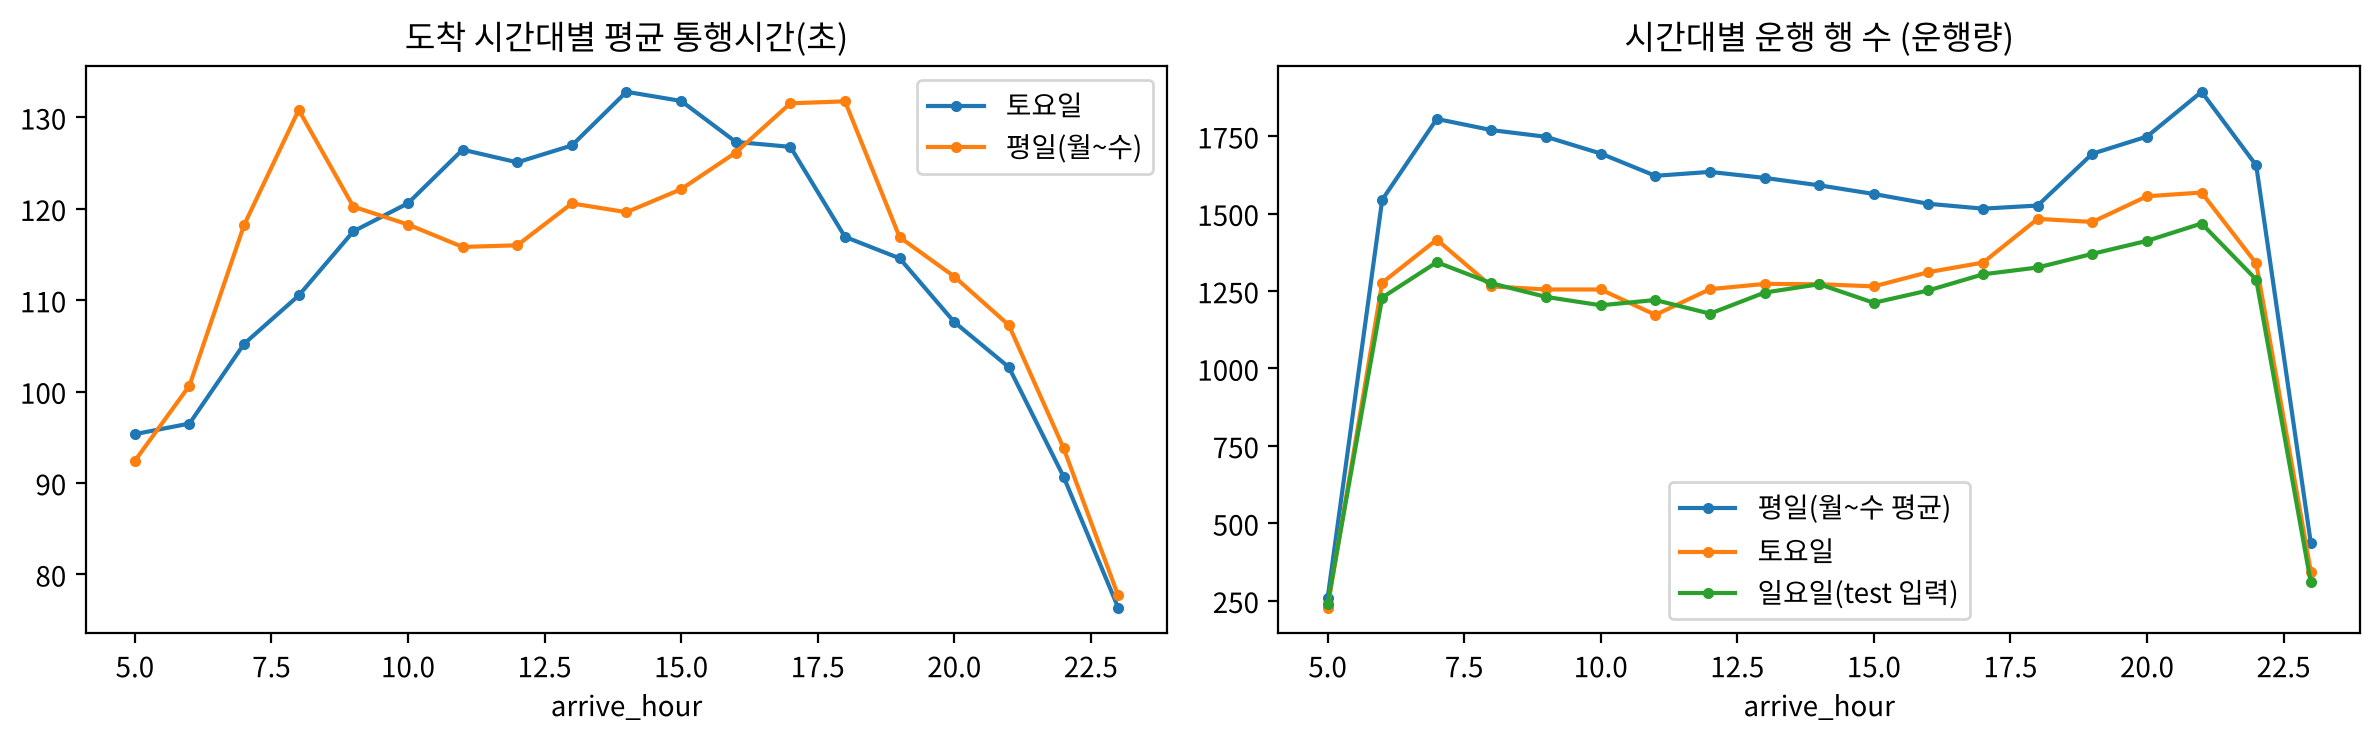

In [7]:
hr = nl.groupby('arrive_hour').agg(평균=('tt_sec', 'mean'), 중앙값=('tt_sec', 'median'), 평소대비=('lr_seg', 'mean'), 변동=('lr_seg', 'std'))
display(hr.round(3).T)
print('노선×시간대 평소 대비:'); display(nl.groupby(['arrive_hour', 'route_nm']).lr_seg.mean().unstack().round(2).T)

kind = np.where(train.is_weekend == 1, '토요일', '평일(월~수)')
h2 = train.groupby([kind, 'arrive_hour']).tt_sec.mean().unstack(0)
cnt = pd.concat([train, test]).groupby(['date', 'arrive_hour']).size().unstack(0)
vol = pd.DataFrame({'평일(월~수 평균)': cnt[['2024-09-23', '2024-09-24', '2024-09-25']].mean(1),
                    '토요일': cnt['2024-09-28'], '일요일(test 입력)': cnt['2024-09-29']})
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
h2.plot(ax=ax[0], marker='o', ms=3); ax[0].set_title('도착 시간대별 평균 통행시간(초)'); ax[0].set_xlabel('arrive_hour')
vol.plot(ax=ax[1], marker='o', ms=3); ax[1].set_title('시간대별 운행 행 수 (운행량)'); ax[1].set_xlabel('arrive_hour')
plt.tight_layout(); plt.show()

## 1-7. 데이터 품질
중복·결측, 극단값, test에 처음 보는 구간이 있는지, 같은 차량의 연속 행에서 정류장 순번이 건너뛰는 곳(끊김)이 있는지.

In [8]:
print('중복 row_id:', int(train.row_id.duplicated().sum()), '| 결측 총합:', int(train.isna().sum().sum()))
sp = train.dist_m / train.tt_sec
print('tt_sec 최소/최대:', train.tt_sec.min(), train.tt_sec.max(), '| 시속 60km 초과 행:', int((sp * 3.6 > 60).sum()))
print('test에서 train에 없는 구간의 행 수:', int((~test.seg.isin(set(train.seg))).sum()), '/', len(test))

cont = ((train.vehicle_id == train.vehicle_id.shift()) & (train.date == train.date.shift()) &
        (train.route_id == train.route_id.shift()) & (train.direction == train.direction.shift()))
gap = cont & (train.stop_seq != train.stop_seq.shift() + 1)
print('연속 행에서 stop_seq가 +1이 아닌 지점(끊김): %d / 연속 행 쌍 %d (%.2f%%)' % (gap.sum(), cont.sum(), gap.sum() / cont.sum() * 100))
print('이전 행의 to_stop == 현재 행의 from_stop 비율:', round((train.from_stop[cont & ~gap].values == train.to_stop.shift()[cont & ~gap].values).mean(), 4))

중복 row_id: 0 | 결측 총합: 0
tt_sec 최소/최대: 7 1775 | 시속 60km 초과 행: 164
test에서 train에 없는 구간의 행 수: 2 / 79942
연속 행에서 stop_seq가 +1이 아닌 지점(끊김): 818 / 연속 행 쌍 106110 (0.77%)
이전 행의 to_stop == 현재 행의 from_stop 비율: 1.0


---
# Part 2. 검증 설계와 기준선

## 2-1. 검증 방법
- test가 **처음 보는 날짜**이므로 검증도 **날짜 단위**: 날짜 하나를 통째로 빼고 나머지로 학습 → 4번(월·화·수·토) 반복.
- 점수는 항상 **월·화·수 평균 / 토요일 / 4일 평균**을 따로 본다.
  토요일 검증은 학습에 평일만 있는 조건이라 **일요일 성능이 아님**.
- 모델·피처 선택은 **월·화·수 평균**으로 하고, 토요일은 참고만 함.
- **채택 규칙**: 월·화·수 평균이 0.10 이상 좋아지고 세 날 모두 좋아져야 채택 후보.
- 정답에서 뽑는 통계(구간 목록 등)는 **폴드의 학습 날짜에서만** 계산하고, 학습 행에 넣는 값은 자기 날짜를 뺀 나머지로 계산해 누수를 막음.

In [9]:
FOLDS = sorted(train.date.unique())                       # 월, 화, 수, 토
FOLD_NAMES = ['월', '화', '수', '토']
def mae(y, p):  return float(np.abs(np.asarray(y) - np.asarray(p)).mean())
def rmse(y, p): return float(np.sqrt(((np.asarray(y) - np.asarray(p)) ** 2).mean()))

BASE = ['route_type', 'direction', 'interval', 'from_lat', 'from_lon', 'to_lat', 'to_lon', 'dlat', 'dlon',
        'stop_seq', 'dist_m', 'arrive_hour', 'is_weekend', 'is_peak']          # + route_id(범주형)
CATS = pd.CategoricalDtype(sorted(train.route_id.unique()))
def make_X(df, feats):
    x = df[feats].copy(); x['route_id'] = df.route_id.astype(CATS); return x

PARAMS_NB = dict(objective='regression_l1', learning_rate=0.05, n_estimators=500, num_leaves=127, min_child_samples=50,
                 subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1, n_jobs=-1)       # 노트북 원본과 비슷한 설정
PARAMS_FINAL = {**PARAMS_NB, 'n_estimators': 1000, 'min_child_samples': 10}                           # 조정 후 설정

def run_cv(feats, params, seeds=(0,), prep=None, checkpoints=None):
    """날짜 하나씩 빼고 학습. 반환: array[시드, 날짜(4)] (checkpoints가 있으면 {트리수: array})."""
    ck = checkpoints or [None]
    out = {k: np.zeros((len(seeds), len(FOLDS))) for k in ck}
    for di, vd in enumerate(FOLDS):
        fit, val = train[train.date != vd].copy(), train[train.date == vd].copy()
        if prep: fit, val = prep(fit, val)
        Xa, Xb = make_X(fit, feats), make_X(val, feats)
        for si, seed in enumerate(seeds):
            m = lgb.LGBMRegressor(**params, random_state=seed).fit(Xa, fit.tt_sec)
            for k in ck:
                out[k][si, di] = mae(val.tt_sec, m.predict(Xb, num_iteration=k) if k else m.predict(Xb))
    return out if checkpoints else out[None]

def summ(arr):
    m = np.asarray(arr).mean(0)
    return {'월': m[0], '화': m[1], '수': m[2], '토': m[3], '월화수평균': m[:3].mean(), '평균4일': m.mean()}

## 2-2. 평균 예측 (모델 없음)
같은 노선·방향·정류장 순번·시간대의 평균. 모델이 넘어야 할 기준선.

In [10]:
k3 = ['route_id', 'direction', 'stop_seq', 'arrive_hour']; k2 = ['route_id', 'direction', 'stop_seq']
def mean_predict(fit, df):
    m3 = fit.groupby(k3).tt_sec.mean().rename('p3'); m2 = fit.groupby(k2).tt_sec.mean().rename('p2')
    x = df[k3].join(m3, on=k3).join(m2, on=k2)
    return x.p3.fillna(x.p2).fillna(fit.tt_sec.mean())

mp = np.array([[mae(train[train.date == vd].tt_sec, mean_predict(train[train.date != vd], train[train.date == vd])) for vd in FOLDS]])
display(pd.DataFrame({'평균 예측': summ(mp)}).T.round(2))

,월,화,수,토,월화수평균,평균4일
평균 예측,29.53,28.46,28.71,37.57,28.9,31.07


## 2-3. LightGBM 기준선 (노트북 원본과 비슷한 설정)
`leaves127, min_child_samples=50, 500트리`, 노트북의 기본 피처. 시드 3개로 돌려 **시드만 바꿨을 때 점수가 얼마나 흔들리는지**도 같이 잰다.

In [11]:
t0 = time.time()
res_base = run_cv(BASE, PARAMS_NB, seeds=(0, 1, 2))
print('걸린 시간 %.0f초' % (time.time() - t0))
tab = pd.DataFrame([summ(res_base[[i]]) for i in range(3)], index=['시드0', '시드1', '시드2'])
display(tab.round(3))
print('시드 간 표준편차 -> 월화수평균 %.3f | 토 %.3f  (이보다 작은 차이는 결론으로 쓰지 않음)' % (tab.월화수평균.std(), tab.토.std()))
BASE_ROW = summ(res_base)
print('\n[기준선: 시드3 평균]', {k: round(v, 3) for k, v in BASE_ROW.items()})

걸린 시간 56초


,월,화,수,토,월화수평균,평균4일
시드0,26.950,26.067,26.183,36.657,26.400,28.964
시드1,26.926,26.088,26.142,36.724,26.385,28.970
시드2,26.909,26.068,26.117,36.941,26.365,29.009


시드 간 표준편차 -> 월화수평균 0.018 | 토 0.149  (이보다 작은 차이는 결론으로 쓰지 않음)

[기준선: 시드3 평균] {'월': np.float64(26.928), '화': np.float64(26.075), '수': np.float64(26.147), '토': np.float64(36.774), '월화수평균': np.float64(26.383), '평균4일': np.float64(28.981)}


---
# Part 3. 오차 분석

수요일을 빼고 학습한 모델로 수요일 오차를 쪼개 본다. **어디가 크게 틀리는가?**

In [12]:
vd = '2024-09-25'
fit, val = train[train.date != vd], train[train.date == vd].copy()
m = lgb.LGBMRegressor(**PARAMS_NB, random_state=0).fit(make_X(fit, BASE), fit.tt_sec)
val['pred'] = m.predict(make_X(val, BASE)); val['ae'] = (val.tt_sec - val.pred).abs()
print('수요일 MAE %.2f' % val.ae.mean())
print('\n[노선별 MAE]'); display(val.groupby('route_nm').ae.agg(['mean', 'size']).round(2).T)
print('[시간대별 MAE]', val.groupby('arrive_hour').ae.mean().round(1).to_dict())

val['정답구간'] = pd.cut(val.tt_sec, [0, 30, 60, 120, 240, 480, 5000])
g = val.groupby('정답구간').ae.agg(['size', 'mean', 'sum'])
g['행%'] = g['size'] / g['size'].sum() * 100; g['오차기여%'] = g['sum'] / g['sum'].sum() * 100
print('\n[정답 크기별: 행 비율 / MAE / 전체 오차에서 차지하는 비중]'); display(g[['행%', 'mean', '오차기여%']].round(1))
print('이름이 같은 구간(same_name): 행 %.2f%%, 오차 비중 %.1f%%, MAE %.0f' % (
      val.same_name.mean() * 100, val[val.same_name].ae.sum() / val.ae.sum() * 100, val[val.same_name].ae.mean()))

수요일 MAE 26.18

[노선별 MAE]


route_nm,1,102,511,605
mean,32.58,24.66,24.31,26.21
size,4511.00,12605.00,5260.00,6511.00


[시간대별 MAE] {5: 20.4, 6: 23.9, 7: 26.5, 8: 31.9, 9: 27.1, 10: 27.1, 11: 25.6, 12: 24.9, 13: 26.9, 14: 26.1, 15: 25.1, 16: 25.8, 17: 27.8, 18: 29.0, 19: 26.8, 20: 24.3, 21: 26.8, 22: 22.1, 23: 18.9}

[정답 크기별: 행 비율 / MAE / 전체 오차에서 차지하는 비중]


,행%,mean,오차기여%
정답구간,,,
"(0, 30]",3.2,17.3,2.1
"(30, 60]",26.1,15.2,15.2
"(60, 120]",34.6,19.4,25.6
"(120, 240]",30.6,31.9,37.3
"(240, 480]",4.4,63.6,10.6
"(480, 5000]",1.2,198.0,9.3


이름이 같은 구간(same_name): 행 1.40%, 오차 비중 7.3%, MAE 136


## 3-2. 오래 걸리는(느린) 구간은 어디인가
구간별 `거리 ÷ 중앙값 통행시간`이 **1.5 m/s 미만**인 구간 (관측 30행 이상).
이름이 같은 구간뿐 아니라 이름이 달라도 속도가 매우 낮은 구간이 있다. 속도에는 정차 시간도 섞여 있으므로, 여기서는 "회차"라고 단정하지 않고 **후보(`is_slow_segment`)**로 부름. 노선 방향의 끝부분인지 함께 확인.

In [13]:
rng = pd.concat([train, test]).groupby(['route_id', 'direction']).stop_seq.agg(['min', 'max'])
sg = train.groupby('seg').agg(노선=('route_nm', 'first'), 방향=('direction', 'first'), n=('tt_sec', 'size'), 중앙값=('tt_sec', 'median'),
                              거리=('dist_m', 'first'), seq=('stop_seq', 'first'), 이름같음=('same_name', 'first'),
                              rid=('route_id', 'first'))
sg['min'] = [rng.loc[(r, d), 'min'] for r, d in zip(sg.rid, sg.방향)]
sg['max'] = [rng.loc[(r, d), 'max'] for r, d in zip(sg.rid, sg.방향)]
sg['속도m_s'] = sg.거리 / sg.중앙값
slow = sg[(sg.n >= 30) & (sg.속도m_s < 1.5)].sort_values('속도m_s')
slow['방향 끝까지 남은 정류장 수'] = slow['max'] - slow.seq
display(slow[['노선', '방향', 'seq', 'min', 'max', '방향 끝까지 남은 정류장 수', '중앙값', '속도m_s', '이름같음']].round(1))

,노선,방향,seq,min,max,방향 끝까지 남은 정류장 수,중앙값,속도m_s,이름같음
seg,,,,,,,,,
DJB8007268>DJB8005504,102,0,47,2,48,1,807.5,0.1,True
DJB8002114>DJB9002115,1,0,21,2,21,0,579.0,0.2,True
DJB8001059>DJB9001059,605,0,37,2,37,0,483.0,0.3,True
DJB8007514>DJB8007563,511,0,35,2,36,1,700.0,0.6,False


---
# Part 4. 피처 실험

**후보를 하나씩** 기준선에 더해 비교한다. (기본값은 시드 1개 — 시드 3개로 보려면 `SEEDS_EXP = (0, 1, 2)`)

| 후보 | 내용 |
|---|---|
| 상대 위치 | `rel_pos` = 해당 노선·방향 안에서 `stop_seq`의 0~1 위치, `remain_stops` = 방향 끝까지 남은 정류장 수 |
| 지리 | 직선거리, 우회비율(`dist_m ÷ 직선거리`), 이동 방향각, 기준점까지 거리 |
| 느린 구간 플래그 | 위 3-2의 느린 구간 목록을 **폴드 학습 날짜에서만** 계산해 0/1로 표시 (학습 행은 자기 날짜를 뺀 나머지로 계산) |
| 시간대×주말 | `arrive_hour + 24 * is_weekend` |
| 노선×시간대 | 노선 번호 × 24 + 시간대 |

모두 기본 설정은 조정 후 설정(`PARAMS_FINAL`)을 사용함.

In [14]:
SEEDS_EXP = (0,)

def hav(lat1, lon1, lat2, lon2):
    R = 6371000.0; p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

center = (train.from_lat.mean(), train.from_lon.mean())
rcode = {r: i for i, r in enumerate(CATS.categories)}
def add_extra(df):
    df = df.copy()
    df['straight_m'] = hav(df.from_lat, df.from_lon, df.to_lat, df.to_lon)
    df['detour'] = df.dist_m / df.straight_m.clip(lower=1)
    df['bearing'] = np.degrees(np.arctan2(df.dlon * np.cos(np.radians(df.from_lat)), df.dlat))
    df['d_center'] = hav(df.from_lat, df.from_lon, center[0], center[1])
    mn = [rng.loc[(r, d), 'min'] for r, d in zip(df.route_id, df.direction)]
    mx = [rng.loc[(r, d), 'max'] for r, d in zip(df.route_id, df.direction)]
    df['rel_pos'] = (df.stop_seq - np.array(mn)) / (np.array(mx) - np.array(mn))
    df['remain_stops'] = np.array(mx) - df.stop_seq
    df['hour_wk'] = df.arrive_hour + 24 * df.is_weekend
    df['route_hour'] = df.route_id.map(rcode) * 24 + df.arrive_hour
    return df
train, test = add_extra(train), add_extra(test)

def slow_set(T, thr=1.5):
    g = T.groupby('seg').agg(med=('tt_sec', 'median'), n=('tt_sec', 'size'), dist=('dist_m', 'first'))
    return set(g[(g.n >= 30) & (g.dist / g.med < thr)].index)
def prep_slow(fit, val):
    f = pd.Series(0, index=fit.index)
    for d in fit.date.unique():
        s = slow_set(fit[fit.date != d]); mk = fit.date == d
        f[mk] = fit.seg[mk].isin(s).astype(int)
    fit['is_slow'] = f; val['is_slow'] = val.seg.isin(slow_set(fit)).astype(int)
    return fit, val

EXPS = {'BASE (조정 후 설정, 기준선)': ([], None),
        '+상대 위치': (['rel_pos', 'remain_stops'], None),
        '+지리 피처': (['straight_m', 'detour', 'bearing', 'd_center'], None),
        '+느린 구간 플래그': (['is_slow'], prep_slow),
        '+시간대×주말': (['hour_wk'], None),
        '+노선×시간대': (['route_hour'], None)}
exp_rows = {}
t0 = time.time()
for name, (extra, prep) in EXPS.items():
    exp_rows[name] = summ(run_cv(BASE + extra, PARAMS_FINAL, seeds=SEEDS_EXP, prep=prep))
    print('%-22s 완료 (%.0f초)' % (name, time.time() - t0), flush=True)

ref = exp_rows['BASE (조정 후 설정, 기준선)']
def verdict(r):
    d = [r[k] - ref[k] for k in ['월', '화', '수']]; dm = r['월화수평균'] - ref['월화수평균']
    if dm <= -0.10 and all(x < 0 for x in d): return '채택 후보'
    if dm >= 0.10 and all(x > 0 for x in d): return '나빠짐'
    return '효과 없음/불분명'
df_exp = pd.DataFrame(exp_rows).T
df_exp['Δ월화수'] = df_exp.월화수평균 - ref['월화수평균']; df_exp['Δ토(참고)'] = df_exp.토 - ref['토']
df_exp['판정'] = [verdict(exp_rows[k]) if not k.startswith('BASE') else '-' for k in df_exp.index]
display(df_exp.round(3))

BASE (조정 후 설정, 기준선)    완료 (44초)


+상대 위치                 완료 (90초)


+지리 피처                 완료 (138초)


+느린 구간 플래그             완료 (181초)


+시간대×주말                완료 (225초)


+노선×시간대                완료 (269초)


,월,화,수,토,월화수평균,평균4일,Δ월화수,Δ토(참고),판정
"BASE (조정 후 설정, 기준선)",26.449,25.697,25.699,37.042,25.948,28.722,0.000,0.000,-
+상대 위치,26.410,25.654,25.740,36.485,25.934,28.572,-0.014,-0.557,효과 없음/불분명
+지리 피처,26.421,25.630,25.755,36.530,25.936,28.584,-0.013,-0.512,효과 없음/불분명
+느린 구간 플래그,26.469,25.637,25.719,36.440,25.942,28.566,-0.006,-0.602,효과 없음/불분명
+시간대×주말,26.377,25.672,25.714,36.948,25.921,28.678,-0.027,-0.093,효과 없음/불분명
+노선×시간대,26.385,25.635,25.701,36.937,25.907,28.664,-0.041,-0.105,효과 없음/불분명


---
# Part 5. 하이퍼파라미터

`num_leaves`(트리 크기), `min_child_samples`(잎 하나에 필요한 최소 행 수), 트리 개수를 비교한다. 트리 개수는 **한 번 학습한 뒤 중간 시점에서 잘라서** 비교하며, 검증 날짜로 멈추는 early stopping은 쓰지 않음. 선택은 월·화·수 평균으로.

`FULL_GRID = True`로 바꾸면 3×3 전체 격자(약 10분 이상)를 돌림.

In [15]:
FULL_GRID = False
CK = [300, 600, 1000]
pairs = list(itertools.product([127, 255, 511], [10, 20, 50])) if FULL_GRID else [(127, 50), (127, 20), (127, 10), (255, 10)]
hp_rows = []; t0 = time.time()
for nl_, mcs in pairs:
    p = {**PARAMS_NB, 'n_estimators': max(CK), 'num_leaves': nl_, 'min_child_samples': mcs}
    res = run_cv(BASE, p, seeds=(0,), checkpoints=CK)
    for k in CK: hp_rows.append({'leaves': nl_, 'mcs': mcs, 'trees': k, **summ(res[k])})
    print('leaves%d mcs%d 완료 (%.0f초)' % (nl_, mcs, time.time() - t0), flush=True)
hp = pd.DataFrame(hp_rows).sort_values('월화수평균')
display(hp.round(3))

leaves127 mcs50 완료 (54초)


leaves127 mcs20 완료 (107초)


leaves127 mcs10 완료 (160초)


leaves255 mcs10 완료 (243초)


,leaves,mcs,trees,월,화,수,토,월화수평균,평균4일
8,127,10,1000,26.449,25.697,25.699,37.042,25.948,28.722
10,255,10,600,26.465,25.678,25.731,37.090,25.958,28.741
11,255,10,1000,26.484,25.694,25.774,37.234,25.984,28.796
5,127,20,1000,26.499,25.705,25.782,36.844,25.995,28.707
7,127,10,600,26.578,25.780,25.807,36.804,26.055,28.742
9,255,10,300,26.584,25.766,25.835,36.829,26.062,28.754
4,127,20,600,26.636,25.794,25.865,36.652,26.098,28.737
2,127,50,1000,26.710,25.873,25.928,36.867,26.171,28.845
1,127,50,600,26.862,25.996,26.093,36.691,26.317,28.910
6,127,10,300,26.982,26.182,26.245,36.530,26.470,28.985


---
# Part 6. 최종 설정과 연습용 test 확인

고정한 설정: `objective=regression_l1, lr=0.05, num_leaves=127, min_child_samples=10, subsample=0.8, colsample_bytree=0.8, 1000트리`, 기본 피처 14개 + `route_id`(범주형).

> **연습용 `test` 점수는 마지막 확인용임.** 이 점수를 보고 설정을 고르지 않음. 학습은 전체 train, 시드 3개의 예측을 평균.

In [16]:
SRC = [os.environ.get('BIS_SRC'), '../../bis-travel-time-practice/src', '../bis-travel-time-practice/src', '../src']
for p in SRC:
    if p and (Path(p) / 'evaluate.py').exists(): sys.path.append(str(Path(p).resolve())); break
try:
    from evaluate import score
except Exception:
    score = None

preds = [lgb.LGBMRegressor(**PARAMS_FINAL, random_state=s).fit(make_X(train, BASE), train.tt_sec).predict(make_X(test, BASE)) for s in (0, 1, 2)]
final_pred = np.mean(preds, axis=0)
sub = pd.DataFrame({'row_id': test.row_id, 'tt_sec': final_pred.round(1)})
os.makedirs('../submissions', exist_ok=True)
sub.to_csv('../submissions/practice_lightgbm_final.csv', index=False)
print(sub.shape, '| 결측', int(sub.tt_sec.isna().sum()), '| row_id 중복', int(sub.row_id.duplicated().sum()))

mean_pred = mean_predict(train, test).values
tmp = test.assign(_ae_final=np.abs(test.tt_sec.values - final_pred), _ae_mean=np.abs(test.tt_sec.values - mean_pred))
print('\n[연습용 test MAE]  평균 예측 %.2f | 최종 설정 %.2f' % (tmp._ae_mean.mean(), tmp._ae_final.mean()))
print('날짜별 MAE(최종 설정):', tmp.groupby('date')._ae_final.mean().round(2).to_dict())
if score:
    r = score(sub, test[['row_id', 'tt_sec']], test)
    print('채점 함수: MAE %.2f RMSE %.2f 첨두 %.2f 비첨두 %.2f' % (r['MAE'], r['RMSE'], r['첨두 MAE'], r['비첨두 MAE']))
    print('노선별', {k: round(v, 2) for k, v in r['노선별 MAE'].items()})

(79942, 2) | 결측 0 | row_id 중복 0

[연습용 test MAE]  평균 예측 29.89 | 최종 설정 27.75
날짜별 MAE(최종 설정): {'2024-09-26': 25.85, '2024-09-27': 27.15, '2024-09-29': 30.98}
채점 함수: MAE 27.75 RMSE 56.54 첨두 29.75 비첨두 26.67
노선별 {'1': 33.69, '102': 27.14, '511': 24.98, '605': 27.23}


---
# Part 7. 실험 기록 요약 (시드 3개 · 전체 설정으로 돌린 값, 자세한 내용은 README)

| 단계 | 월·화·수 평균 MAE | 비고 |
|---|---|---|
| 평균 예측 (모델 없음) | 28.90 | 기준선 |
| LightGBM, 노트북과 비슷한 설정 (leaves127, mcs50, 500트리) | 26.383 | 시드 3개 평균 |
| 피처 추가: 상대 위치 / 지리 / 느린 구간 플래그 (같은 설정) | 각각 −0.064 / −0.040 / −0.041 | 기준(−0.10) 미달 |
| **조정 후 설정 (leaves127, mcs10, 1000트리)** | **25.942** | **−0.441, 세 날 모두 개선** |
| 조정 후 설정에서 피처 재검증 | −0.012 ~ −0.028 | 효과 없음 |

**연습용 test (목·금·일, 마지막 확인)**: 평균 예측 29.89 → 노트북 원본 약 27.97~27.99 → 조정 후 설정 27.75 (날짜별 25.85 / 27.15 / 30.98).

## 한계와 주의
- **일요일은 검증할 방법이 없음.** 학습에 주말은 토요일 하루뿐이고, 토요일 검증은 평일만 학습한 조건이라 일요일 성능이 아님.
- 토요일 폴드는 시드·피처에 따라 크게 흔들림(시드 표준편차 약 0.15) — 결론에 쓰지 않음.
- 설정을 월·화·수 점수로 골랐기 때문에 실제 새 날짜에서의 개선은 −0.44보다 작을 수 있음 (연습용 test에서는 약 −0.22).
- 대기(느린) 구간은 전체 오차의 약 12%를 차지하지만, 따로 다뤄도 현실적인 개선은 약 0.09 수준.

## 다음 단계
앙상블(CatBoost·XGBoost) — 같은 날짜 분할의 검증 예측을 섞어 MAE가 줄어드는지 확인하고, 혼합 비율도 검증 결과로 정함.